***
Welcome! 

In this notebook, we will delve into the practical implementation of our Continuous Bag of Words (CBOW) model on real-world text data, paving the way to train highly effective word vectors. The significance of word vectors lies in their ability to capture semantic relationships between words, enabling us to unlock a deeper understanding of language and its context.
<br>
<br>
We will use multiple concepts learned througout the course such as **Word Vectors, Retrieving data from the Web and the NLTK Library.** 
***

In [15]:
# Importing our libraries
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics.pairwise import cosine_similarity
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
import string
import numpy as np
import pandas as pd
import gc

In [16]:
# Run this Code to approximate reproducibility
SEED = 123456
import os
import random as rn
from tensorflow.random import set_seed

os.environ['PYTHONHASHSEED']=str(SEED)
np.random.seed(SEED)
set_seed(SEED)
rn.seed(SEED)

We will use a bundled text snapshot of three Wikipedia articles (`Europe`, `America` and `Africa`) so this notebook does not depend on live API availability:

In [17]:
from pathlib import Path

corpus_relative_path = Path(
    "60.Natural-Language-Processing-(NLP)-in-Python/Course-Material/"
    "Natural Language Processing in Python/07 - Word2Vec and Neural Networks Word Vectors/"
    "cbow_train/training_base.txt"
)
corpus_candidates = [
    parent / "cbow_train/training_base.txt"
    for parent in (Path.cwd(), *Path.cwd().parents)
]
corpus_candidates.extend(
    parent / corpus_relative_path
    for parent in (Path.cwd(), *Path.cwd().parents)
)
corpus_path = next(
    (candidate for candidate in corpus_candidates if candidate.is_file()),
    None,
)
if corpus_path is None:
    raise FileNotFoundError(
        "Could not locate cbow_train/training_base.txt. "
        "Run this notebook from the repository or its notebook directory."
    )

training_base = corpus_path.read_text(encoding="utf-8")

And now, we join all the corpus in a large training base (corpus).

In [18]:
# The training corpus was loaded from the bundled text file above.

Note: If you want to replicate exactly what I've done in the lectures, uncomment the line of code below to read a static file with the data (as the wikipedia pages may be edited in the meantime). If you don't, your vectors will be approximately the same but you may have slightly different order in the similarities and word examples.

In [19]:
#with open('./cbow_train/training_base.txt', 'r', encoding='utf-8') as f:
#    training_base = f.read()

We will also remove punctuation for this exercise - let's use the handy `translate` function to do that:

In [20]:
training_base = (
    training_base
    .translate(
        str.maketrans('', '', string.punctuation)
    )
)

In [21]:
len(training_base)

245488

And now, of course.. **tokenization!**

In [22]:
training_tokenized = word_tokenize(training_base.lower())

In [23]:
training_tokenized

['europe',
 'is',
 'a',
 'continent',
 'comprising',
 'the',
 'westernmost',
 'peninsulas',
 'of',
 'eurasia',
 'located',
 'entirely',
 'in',
 'the',
 'northern',
 'hemisphere',
 'and',
 'mostly',
 'in',
 'the',
 'eastern',
 'hemisphere',
 'it',
 'shares',
 'the',
 'continental',
 'landmass',
 'of',
 'afroeurasia',
 'with',
 'both',
 'africa',
 'and',
 'asia',
 'it',
 'is',
 'bordered',
 'by',
 'the',
 'arctic',
 'ocean',
 'to',
 'the',
 'north',
 'the',
 'atlantic',
 'ocean',
 'to',
 'the',
 'west',
 'the',
 'mediterranean',
 'sea',
 'to',
 'the',
 'south',
 'and',
 'asia',
 'to',
 'the',
 'east',
 'europe',
 'is',
 'commonly',
 'considered',
 'to',
 'be',
 'separated',
 'from',
 'asia',
 'by',
 'the',
 'watershed',
 'of',
 'the',
 'ural',
 'mountains',
 'the',
 'ural',
 'river',
 'the',
 'caspian',
 'sea',
 'the',
 'greater',
 'caucasus',
 'the',
 'black',
 'sea',
 'and',
 'the',
 'waterways',
 'of',
 'the',
 'turkish',
 'straitseurope',
 'covers',
 'about',
 '1018',
 'million',
 'k

For this exercise, we'll not remove stop words but feel free to remove them if you want.

Let's build our vocabulary:

In [24]:
vocab = list(
    set(training_tokenized)
)

In [25]:
vocab.sort()

In [26]:
print('We have about {} words in our training base.'.format(len(vocab)))

We have about 5529 words in our training base.


We will build 5.558 different vectors in this exercise.

In [27]:
word_representations = np.identity(len(vocab))

A simple way to generate our one-hot vectors for each word is to use the identity matrix with the size of our vocabulary as we are doing above.

In [28]:
word_representations

array([[1., 0., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 0., 0., 1.]])

In [29]:
vocab_vectors = {}

for index, element in enumerate(vocab):
    vocab_vectors[element] = word_representations[index]

Now we have each word mapped into a vector of len `n` where `n` is the number of words.

In [30]:
vocab_vectors

{'02': array([1., 0., 0., ..., 0., 0., 0.]),
 '0792236955': array([0., 1., 0., ..., 0., 0., 0.]),
 '09': array([0., 0., 1., ..., 0., 0., 0.]),
 '1': array([0., 0., 0., ..., 0., 0., 0.]),
 '10': array([0., 0., 0., ..., 0., 0., 0.]),
 '100': array([0., 0., 0., ..., 0., 0., 0.]),
 '1000': array([0., 0., 0., ..., 0., 0., 0.]),
 '10000': array([0., 0., 0., ..., 0., 0., 0.]),
 '100000': array([0., 0., 0., ..., 0., 0., 0.]),
 '100th': array([0., 0., 0., ..., 0., 0., 0.]),
 '1018': array([0., 0., 0., ..., 0., 0., 0.]),
 '102': array([0., 0., 0., ..., 0., 0., 0.]),
 '103': array([0., 0., 0., ..., 0., 0., 0.]),
 '105': array([0., 0., 0., ..., 0., 0., 0.]),
 '1054': array([0., 0., 0., ..., 0., 0., 0.]),
 '108': array([0., 0., 0., ..., 0., 0., 0.]),
 '1095': array([0., 0., 0., ..., 0., 0., 0.]),
 '10th': array([0., 0., 0., ..., 0., 0., 0.]),
 '10°': array([0., 0., 0., ..., 0., 0., 0.]),
 '11': array([0., 0., 0., ..., 0., 0., 0.]),
 '11000': array([0., 0., 0., ..., 0., 0., 0.]),
 '1127152': array([

Now let's create a function that when we given our sentences, it will produce a list of words and context.
<br>
<br>
Why are we building this in another list? Because we will have the same word represented with different context in our sentences. 
<br>
<br>
Another way to do this is to consider the average "context" for a single word - and each word would only be represented once in the training base.

In [31]:
def retrieve_word_neighbors(sentence, neighbors):
    '''
    Retrieves word and neighbor(context) of size
    neighbors into two separate lists.
    
    Arguments:
    - Sentence(str): The sentence to retrieve
    words and context words.
    - Neighbors(int): The size of the window to
    consider context.
    
    Returns:
    - word_keys_sentence(list): Word list;
    - context_words(list): A list with the context
    words for each word of index i
    '''
    word_keys_sentence = []
    context_words = []    
    
    for index, word in enumerate(sentence):
        
        # Build start
        # Build finish
        start = index-neighbors        
        finish = index+neighbors
        
        # Get neighbor words
        neighbor_words = sentence[start:finish+1]
        # Generate context
        word_context = (
            neighbor_words[:neighbors]
            +
            neighbor_words[neighbors+1:]
        )
        
        # We only append the context if we have enough 
        # neighbors
        if len(word_context) >= neighbors*2:
            word_keys_sentence.append(word)
            context_words.append(word_context)
            
    return word_keys_sentence, context_words

Let's see two examples of word and context using 3 neighbors:

In [32]:
retrieve_word_neighbors(training_tokenized, 3)[0][542]

'the'

For the word 'peninsula' in this sentence, the context is:

In [33]:
retrieve_word_neighbors(training_tokenized, 3)[1][542]

['states', 'led', 'to', 'formation', 'of', 'the']

Makes sense as the context and the word would form the sentence:
    - `states led to the formation of the`

Another example:

In [34]:
retrieve_word_neighbors(training_tokenized, 3)[0][1]

'comprising'

In [35]:
retrieve_word_neighbors(training_tokenized, 3)[1][1]

['is', 'a', 'continent', 'the', 'westernmost', 'peninsulas']

Let's save the entire data into two objects:

In [36]:
word_keys, context_window = retrieve_word_neighbors(training_tokenized, 3)

More examples of word and context:

In [37]:
word_keys[1000]

'to'

In [38]:
context_window[1000]

['iceland', 'is', 'considered', 'be', 'part', 'of']

In [39]:
word_keys[200]

'further'

In [40]:
context_window[200]

['america', 'is', 'severe', 'from', 'the', 'sea']

The length of our `word_keys` and `context_window` must be the same:

In [41]:
print(len(word_keys))
print(len(context_window))

39230
39230


Let's now build our features and our target variable. Remember that in our training base, the same word is repeated multiple times. You can also try to average the training vectors for the same word during the training, as an alternative.

NOTE: If your computer has some trouble running the line below, try one of the following:
- Importing the library gc with `import gc` and run `gc.collect()`
- Try to run the notebook with less articles (taking out one of the continent pages from the training base).

In [42]:
train_word_size = len(word_keys)
vocab_size = len(vocab)

y = np.zeros([train_word_size, vocab_size])
X = np.zeros([train_word_size, vocab_size])

Let's build the prediction and target vectors - we will use three neighbors on each side of the word, a window of 6:

In [43]:
neighbors = 3
for index, word in enumerate(word_keys):
    y[index,:] = vocab_vectors[word]
    aux_array = np.zeros([1, vocab_size])
    
    for neighbour in context_window[index]:
        aux_array = aux_array+vocab_vectors[neighbour]
    
    X[index,:] = (aux_array/(neighbors*2))[0]

And now we will train our Neural Network:

In [44]:
from keras.models import Sequential
from keras.layers import Dense

We can also build a large hidden layer (our word vectors will be larger). Here we are setting our vector layers to shape 40:

In [45]:
model = Sequential()
model.add(Dense(40, input_dim=vocab_size, activation='relu'))
model.add(Dense(vocab_size, input_dim=40, activation='softmax'))

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-10-13 22:42:36.203562: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-10-13 22:42:36.203762: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-10-13 22:42:36.203766: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.00 GB
I0000 00:00:1791911556.203776 2706093 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1791911556.203808 2706093 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/t

The fit process will take a bit to run - let's use validation split to check the accuracy of the algorithm in a holdout set:

In [46]:
model.fit(
    X, 
    y, 
    epochs=100, 
    batch_size=100,
    validation_split=0.2
)

Epoch 1/100


2026-10-13 22:42:38.895028: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


314/314 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.0956 - loss: 7.7744 - val_accuracy: 0.0848 - val_loss: 6.9148
Epoch 2/100
314/314 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.0967 - loss: 6.7008 - val_accuracy: 0.0848 - val_loss: 6.8421
Epoch 3/100
314/314 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.0968 - loss: 6.6352 - val_accuracy: 0.0862 - val_loss: 6.7898
Epoch 4/100
314/314 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.1007 - loss: 6.5760 - val_accuracy: 0.0927 - val_loss: 6.7381
Epoch 5/100
314/314 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.1086 - loss: 6.5186 - val_accuracy: 0.0990 - val_loss: 6.6853
Epoch 6/100
314/314 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.1144 - loss: 6.4624 - val_accuracy: 0.1013 - val_loss: 6.6312
Epoch 7/100
314/314 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.1183 - loss: 6.4059 - val_accuracy: 0.1036 - val_loss: 6.5738
Epoch 8/100
314/314 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.1216 - loss: 6.3474 - val_accuracy

Let's check the predictions of our neural network model and how it is predicting a center word from a context:

In [47]:
prediction_test = model.predict(X)

1226/1226 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


In [48]:
# Turning our predictions into one-hot vectors
for index, element in enumerate(prediction_test):
    predicted = element.argmax()
    prediction_test[index,:] = 0 
    prediction_test[index, predicted] = 1

In [49]:
len(prediction_test)

39230

Let's check the `accuracy` for our model - how many words did we got right?

In [50]:
prediction_test

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

In [51]:
accuracy_score(y, prediction_test)

0.5887331124139689

Great! We have around 82% of accuracy (your results may be slightly different after running the code, but you should have something around this balue) - this is a nice result.
<br>
<br>
Let's visualize some predictions:

In [52]:
def print_prediction(context, index, prediction_vector):
    
    context_index = context[index]
    
    print('For sentence: '+' '.join(context_index[0:2])+' '+' '.join(context_index[2:]))
    predicted_word = prediction_vector[index]
    
    for index_word, array in enumerate(vocab_vectors.values()):
        if np.array_equal(predicted_word, array):
            word = vocab[index_word]
    print('The predicted word is {}'.format(word))

In [53]:
print_prediction(context_window, 2424, prediction_test)

For sentence: pallas as a that once connected
The predicted word is term


For the context `and subsequently was as a natural` the predicted word is `proposed` which is indeed correct!

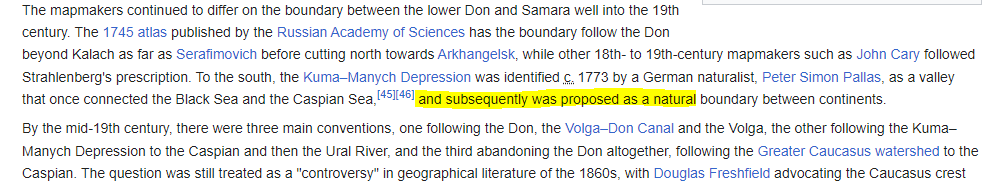

Let's retrieve our stored **word embeddings**:

In [54]:
embeddings = [layer.get_weights() for layer in model.layers]

In [55]:
embeddings_layer = embeddings[0][0]
embeddings_layer_2 = embeddings[1][0]

In [56]:
embeddings_layer_2.T.shape

(5529, 40)

In [57]:
word_embeddings = (embeddings_layer_2.T+embeddings_layer)/2

And producing similarities between vectors based on cosine distance:

In [58]:
word_embeddings = pd.DataFrame(word_embeddings, index=vocab)

In [59]:
word_embeddings_sim = pd.DataFrame(
    cosine_similarity(word_embeddings),
    columns=vocab,
    index=vocab
)

/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [60]:
def get_most_and_least_similar_words(word):
    word = word.lower()
    if word not in word_embeddings_sim.columns:
        print(f"{word!r} is not present in the training vocabulary.")
        return None

    similarities = word_embeddings_sim[word].sort_values(ascending=False)
    return similarities.head(15), similarities.tail(15)

Finally, let's check some the most similar and dissimilar words for certain tokens:

In [61]:
get_most_and_least_similar_words('english')

(english              1.000000
 colonies             0.672728
 leased               0.594930
 tribal               0.550882
 taiwan               0.540253
 severe               0.535030
 adult                0.533757
 conflictseuropean    0.530460
 though               0.528596
 alaska               0.523521
 local                0.514595
 preserved            0.514163
 dissenting           0.507791
 thirteen             0.499711
 azerbaijan           0.496607
 Name: english, dtype: float32,
 instrument         -0.474992
 first              -0.479034
 wyoming            -0.481972
 crosssectional     -0.482967
 strahlenberg       -0.487094
 guaranteed         -0.490928
 equals             -0.492346
 siege              -0.494384
 citys              -0.497416
 depressionbarack   -0.516122
 transport          -0.530948
 historic           -0.547725
 publication        -0.559717
 12794              -0.573718
 nationstate        -0.594244
 Name: english, dtype: float32)

Interesting results! Let's see more examples:

In [62]:
get_most_and_least_similar_words('mexico')

(mexico            1.000000
 canada            0.779326
 2010s             0.563684
 gulf              0.532199
 africans          0.523204
 addition          0.511025
 florida           0.499817
 populous          0.467548
 austriahungary    0.465366
 with              0.460022
 lines             0.458465
 centre            0.457227
 borders           0.448399
 weimar            0.444359
 again             0.443204
 Name: mexico, dtype: float32,
 dickinson         -0.560790
 norwegian         -0.563432
 published         -0.566757
 code              -0.574826
 nonindoeuropean   -0.575872
 bethesda          -0.578927
 off               -0.582607
 softworks         -0.583565
 valve             -0.583862
 9780495913115     -0.595987
 referendum        -0.602287
 naturalist        -0.603486
 virtually         -0.610829
 resources         -0.627049
 scholars          -0.718298
 Name: mexico, dtype: float32)

Our vectors are really good! Even with a small portion of text we were able to get interesting vectors from our data.

In [63]:
get_most_and_least_similar_words('government')

(government           1.000000
 federal              0.647477
 citizenship          0.643993
 grassroots           0.625705
 sovereignty          0.622086
 applied              0.620926
 official             0.616058
 courts               0.608821
 rulings              0.607003
 requirements         0.600109
 leave                0.585652
 values               0.578510
 initiatives          0.573699
 respective           0.570143
 futuresgovernment    0.565190
 Name: government, dtype: float32,
 476               -0.526484
 1980s             -0.535852
 1st               -0.537140
 greekspeaking     -0.537940
 negro             -0.538368
 wall              -0.551608
 journal           -0.552943
 1969              -0.553479
 ellington         -0.555907
 early             -0.559031
 cromagnons        -0.563787
 balkan            -0.572886
 riots             -0.625846
 stonewall         -0.626460
 austrohungarian   -0.637573
 Name: government, dtype: float32)

In [64]:
get_most_and_least_similar_words('lincoln')

(lincoln       1.000000
 abraham       0.804063
 justinian     0.736983
 49            0.649619
 outgoing      0.647114
 attending     0.644490
 woodrow       0.631233
 packs         0.630764
 1980          0.626220
 fears         0.626090
 rejoined      0.625579
 republican    0.615916
 archduke      0.609699
 1954          0.605488
 capacity      0.600171
 Name: lincoln, dtype: float32,
 pursuit          -0.452543
 seized           -0.455307
 grasslands       -0.456415
 contributed      -0.460007
 euratom          -0.462803
 curtain          -0.469860
 azov             -0.475106
 distribution     -0.481492
 outcome          -0.504775
 austriahungary   -0.507524
 gulf             -0.512765
 connecting       -0.516864
 dissolution      -0.546096
 the              -0.554733
 fauna            -0.592777
 Name: lincoln, dtype: float32)

In [65]:
get_most_and_least_similar_words('clergy')

(clergy           1.000000
 caribbean        0.791765
 nobility         0.760505
 grasslands       0.747430
 cork             0.743457
 rockies          0.706220
 pacificstates    0.704618
 thirdmost        0.704469
 movies           0.701826
 drivethrough     0.688487
 originated       0.682736
 1920s            0.673619
 defeat           0.660407
 papacy           0.657115
 epicenter        0.655432
 Name: clergy, dtype: float32,
 face             -0.449147
 dorothea         -0.450726
 populations      -0.452889
 uninhabited      -0.458780
 broad            -0.462171
 gen              -0.462181
 eye              -0.462499
 advances         -0.462593
 values           -0.467249
 edward           -0.504754
 discovery        -0.504996
 constitutional   -0.507136
 angeliki         -0.530154
 families         -0.561201
 europetoday      -0.588237
 Name: clergy, dtype: float32)

In [66]:
get_most_and_least_similar_words('science')

(science         1.000000
 lesser          0.639391
 florence        0.634387
 resignation     0.626282
 ecosystems      0.618712
 stagnation      0.612501
 explorations    0.612090
 bases           0.604685
 britannia       0.597465
 46              0.596113
 technology      0.584426
 warfare         0.583876
 reexpanded      0.581836
 conquests       0.577244
 neoliberal      0.576369
 Name: science, dtype: float32,
 moving         -0.315146
 considered     -0.317263
 sports         -0.318093
 additional     -0.318700
 consumed       -0.319469
 prairie        -0.322234
 precolumbian   -0.323714
 him            -0.323720
 industry       -0.326336
 alfred         -0.326982
 follow         -0.328485
 shaped         -0.330003
 site           -0.334717
 alongside      -0.335604
 fertile        -0.394469
 Name: science, dtype: float32)

In [67]:
get_most_and_least_similar_words('racism')

(racism           1.000000
 confront         0.881288
 martin           0.796723
 systemic         0.754802
 brutality        0.733707
 nailed           0.704008
 lewis            0.688805
 improving        0.685417
 nonviolence      0.680714
 9780521849784    0.676937
 laurasia         0.676544
 proposal         0.676048
 theologian       0.671719
 undocumented     0.668481
 litchfield       0.668191
 Name: racism, dtype: float32,
 timein       -0.490972
 the          -0.497888
 favor        -0.499806
 tornadoes    -0.500983
 eastward     -0.516702
 populous     -0.538312
 network      -0.541714
 rank         -0.542194
 1994         -0.547964
 forum        -0.551468
 likewise     -0.555649
 ii           -0.569894
 39           -0.574399
 superpower   -0.615898
 2022         -0.628671
 Name: racism, dtype: float32)

In [68]:
get_most_and_least_similar_words('great')

(great           1.000000
 souththe        0.719389
 1871            0.684439
 1315            0.681997
 seaboard        0.669795
 1937            0.667756
 awakening       0.657331
 ivan            0.654376
 southeastthe    0.649043
 worker          0.644711
 hudson          0.640628
 988             0.640601
 iii             0.634080
 consolidated    0.630784
 imminent        0.627858
 Name: great, dtype: float32,
 administer    -0.437579
 achievement   -0.439494
 aviation      -0.443149
 15            -0.452262
 attains       -0.452809
 40            -0.454568
 monaco        -0.455668
 unique        -0.469163
 algonquian    -0.469792
 quarter       -0.476814
 families      -0.495039
 ordinary      -0.497890
 highincome    -0.501211
 beekes        -0.525062
 robert        -0.598811
 Name: great, dtype: float32)

Some word vectors extracted will always have an influence from the text where they were trained on. For example, `apple` embedding will have more similarity with the company `Apple` than the `apple` fruit:

In [69]:
get_most_and_least_similar_words('apple')

(apple             1.000000
 att               0.830603
 paramount         0.825365
 fried             0.768265
 disney            0.757836
 cocacola          0.753520
 frank             0.750547
 henry             0.740820
 google            0.728481
 amazon            0.725666
 michelangelo      0.713835
 chicken           0.708544
 netflix           0.697330
 pie               0.682099
 anthropologist    0.681153
 Name: apple, dtype: float32,
 jewish           -0.527703
 selfgovernance   -0.528104
 devolved         -0.530915
 seven            -0.535067
 homeland         -0.535574
 plunder          -0.537190
 source           -0.539977
 shores           -0.540556
 capital          -0.548732
 theatre          -0.554857
 wolf             -0.583511
 400000           -0.598806
 tsardom          -0.608599
 course           -0.628584
 thousands        -0.637742
 Name: apple, dtype: float32)

For such a small training base, it's normal that the least similar words are less meaningful than the most similar.

As a challenge, can you try to produce word vectors with `stop words` and see the result?

As we have seen in this notebook, word vectors are very powerful, even when trained on few sentences and a small corpus. Next we will see an implementation of Word2Vec in Python that was already pre-trained on millions of words!

In [70]:
# Reuse the bundled corpus loaded earlier in the notebook.

In [71]:
# Reuse the bundled corpus loaded earlier in the notebook.


In [72]:
len(training_base)

245488

In [73]:
training_base[0:100]

'Europe is a continent comprising the westernmost peninsulas of Eurasia located entirely in the North'

In [74]:
import string
training_base = (
    training_base.translate(
        str.maketrans('','', string.punctuation)
    )
)

In [75]:
training_base[0:250]

'Europe is a continent comprising the westernmost peninsulas of Eurasia located entirely in the Northern Hemisphere and mostly in the Eastern Hemisphere It shares the continental landmass of AfroEurasia with both Africa and Asia It is bordered by the '

In [76]:
from nltk.tokenize import word_tokenize

In [77]:
training_tokenized = word_tokenize(training_base.lower())
training_tokenized

['europe',
 'is',
 'a',
 'continent',
 'comprising',
 'the',
 'westernmost',
 'peninsulas',
 'of',
 'eurasia',
 'located',
 'entirely',
 'in',
 'the',
 'northern',
 'hemisphere',
 'and',
 'mostly',
 'in',
 'the',
 'eastern',
 'hemisphere',
 'it',
 'shares',
 'the',
 'continental',
 'landmass',
 'of',
 'afroeurasia',
 'with',
 'both',
 'africa',
 'and',
 'asia',
 'it',
 'is',
 'bordered',
 'by',
 'the',
 'arctic',
 'ocean',
 'to',
 'the',
 'north',
 'the',
 'atlantic',
 'ocean',
 'to',
 'the',
 'west',
 'the',
 'mediterranean',
 'sea',
 'to',
 'the',
 'south',
 'and',
 'asia',
 'to',
 'the',
 'east',
 'europe',
 'is',
 'commonly',
 'considered',
 'to',
 'be',
 'separated',
 'from',
 'asia',
 'by',
 'the',
 'watershed',
 'of',
 'the',
 'ural',
 'mountains',
 'the',
 'ural',
 'river',
 'the',
 'caspian',
 'sea',
 'the',
 'greater',
 'caucasus',
 'the',
 'black',
 'sea',
 'and',
 'the',
 'waterways',
 'of',
 'the',
 'turkish',
 'straitseurope',
 'covers',
 'about',
 '1018',
 'million',
 'k

In [78]:
len(training_tokenized)

39236

In [79]:
len(set(training_tokenized))

5529

In [80]:
from nltk.corpus import stopwords
sw = stopwords.words('english')
sw

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [81]:
training_tokenized_no_sw = [word for word in training_tokenized if word not in sw]

In [82]:
len(set(training_tokenized_no_sw))

5419

In [83]:
training_tokenized_no_sw

['europe',
 'continent',
 'comprising',
 'westernmost',
 'peninsulas',
 'eurasia',
 'located',
 'entirely',
 'northern',
 'hemisphere',
 'mostly',
 'eastern',
 'hemisphere',
 'shares',
 'continental',
 'landmass',
 'afroeurasia',
 'africa',
 'asia',
 'bordered',
 'arctic',
 'ocean',
 'north',
 'atlantic',
 'ocean',
 'west',
 'mediterranean',
 'sea',
 'south',
 'asia',
 'east',
 'europe',
 'commonly',
 'considered',
 'separated',
 'asia',
 'watershed',
 'ural',
 'mountains',
 'ural',
 'river',
 'caspian',
 'sea',
 'greater',
 'caucasus',
 'black',
 'sea',
 'waterways',
 'turkish',
 'straitseurope',
 'covers',
 '1018',
 'million',
 'km2',
 '393',
 'million',
 'sq',
 'mi',
 '2',
 'earths',
 'surface',
 '68',
 'land',
 'area',
 'making',
 'secondsmallest',
 'continent',
 'using',
 'sevencontinent',
 'model',
 'politically',
 'europe',
 'divided',
 'fifty',
 'sovereign',
 'states',
 'russia',
 'largest',
 'populous',
 'spanning',
 '39',
 'continent',
 'comprising',
 '15',
 'population',
 'e

In [84]:
curated_words = []
for word in training_tokenized_no_sw:
    if word.isalpha():
        curated_words.append(word)

In [85]:
len(set(curated_words))

4909

In [86]:
vocab = list(set(curated_words))
vocab.sort()
vocab

['abandoning',
 'abbreviation',
 'abc',
 'abolished',
 'abolishment',
 'abolition',
 'abolitionism',
 'abortion',
 'abovementioned',
 'abraham',
 'abroad',
 'absorbed',
 'abstract',
 'abundant',
 'aca',
 'academic',
 'academics',
 'academy',
 'accelerated',
 'accepted',
 'access',
 'accidents',
 'accompanied',
 'accomplishment',
 'according',
 'accordingly',
 'account',
 'accounted',
 'accounting',
 'accounts',
 'accumulated',
 'accurate',
 'achaemenid',
 'achieve',
 'achieved',
 'achievement',
 'acquire',
 'acquired',
 'acquisition',
 'acquitted',
 'across',
 'act',
 'action',
 'active',
 'activision',
 'activities',
 'activitiesof',
 'actors',
 'acts',
 'actual',
 'adams',
 'adapted',
 'add',
 'added',
 'addition',
 'additional',
 'addressing',
 'adhere',
 'adheres',
 'adirondack',
 'adjacent',
 'adjective',
 'administer',
 'administered',
 'administers',
 'administration',
 'administrative',
 'admission',
 'admitted',
 'admitting',
 'adolescents',
 'adolf',
 'adopt',
 'adopted',
 'a

In [87]:
import numpy as np
np.identity(len(vocab))

array([[1., 0., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 0., 0., 1.]])

In [88]:
np.identity(len(vocab)).shape

(4909, 4909)

In [89]:
vocab_representations = np.identity(len(vocab))

In [90]:
vocab_arrays = {}

for index, word in enumerate(vocab):
    vocab_arrays[word] = vocab_representations[index]

vocab_arrays

{'abandoning': array([1., 0., 0., ..., 0., 0., 0.]),
 'abbreviation': array([0., 1., 0., ..., 0., 0., 0.]),
 'abc': array([0., 0., 1., ..., 0., 0., 0.]),
 'abolished': array([0., 0., 0., ..., 0., 0., 0.]),
 'abolishment': array([0., 0., 0., ..., 0., 0., 0.]),
 'abolition': array([0., 0., 0., ..., 0., 0., 0.]),
 'abolitionism': array([0., 0., 0., ..., 0., 0., 0.]),
 'abortion': array([0., 0., 0., ..., 0., 0., 0.]),
 'abovementioned': array([0., 0., 0., ..., 0., 0., 0.]),
 'abraham': array([0., 0., 0., ..., 0., 0., 0.]),
 'abroad': array([0., 0., 0., ..., 0., 0., 0.]),
 'absorbed': array([0., 0., 0., ..., 0., 0., 0.]),
 'abstract': array([0., 0., 0., ..., 0., 0., 0.]),
 'abundant': array([0., 0., 0., ..., 0., 0., 0.]),
 'aca': array([0., 0., 0., ..., 0., 0., 0.]),
 'academic': array([0., 0., 0., ..., 0., 0., 0.]),
 'academics': array([0., 0., 0., ..., 0., 0., 0.]),
 'academy': array([0., 0., 0., ..., 0., 0., 0.]),
 'accelerated': array([0., 0., 0., ..., 0., 0., 0.]),
 'accepted': array([

In [91]:
vocab[-1]

'歐羅巴洲'

In [92]:
vocab_arrays['歐羅巴洲']

array([0., 0., 0., ..., 0., 0., 1.])

In [93]:
def retrieve_word_neighbors(sentence,neighbors):
    word_keys_sentence = []
    context_words = []
    for index,word in enumerate(sentence):
        start = index-neighbors
        finish = index+neighbors
        neighbor_words = sentence[start:finish+1]
        word_context = (
            neighbor_words[:neighbors]
            +
            neighbor_words[neighbors+1:]
        )
        if len(word_context) >= neighbors*2:
            word_keys_sentence.append(word)
            context_words.append(word_context)
    return word_keys_sentence,context_words

In [94]:
curated_words

['europe',
 'continent',
 'comprising',
 'westernmost',
 'peninsulas',
 'eurasia',
 'located',
 'entirely',
 'northern',
 'hemisphere',
 'mostly',
 'eastern',
 'hemisphere',
 'shares',
 'continental',
 'landmass',
 'afroeurasia',
 'africa',
 'asia',
 'bordered',
 'arctic',
 'ocean',
 'north',
 'atlantic',
 'ocean',
 'west',
 'mediterranean',
 'sea',
 'south',
 'asia',
 'east',
 'europe',
 'commonly',
 'considered',
 'separated',
 'asia',
 'watershed',
 'ural',
 'mountains',
 'ural',
 'river',
 'caspian',
 'sea',
 'greater',
 'caucasus',
 'black',
 'sea',
 'waterways',
 'turkish',
 'straitseurope',
 'covers',
 'million',
 'million',
 'sq',
 'mi',
 'earths',
 'surface',
 'land',
 'area',
 'making',
 'secondsmallest',
 'continent',
 'using',
 'sevencontinent',
 'model',
 'politically',
 'europe',
 'divided',
 'fifty',
 'sovereign',
 'states',
 'russia',
 'largest',
 'populous',
 'spanning',
 'continent',
 'comprising',
 'population',
 'europe',
 'total',
 'population',
 'million',
 'world

In [95]:
word_keys,context_window = retrieve_word_neighbors(curated_words,2)

In [96]:
word_keys[2]

'peninsulas'

In [97]:
context_window[2]

['comprising', 'westernmost', 'eurasia', 'located']

In [98]:
word_keys[3]

'eurasia'

In [99]:
context_window[3]

['westernmost', 'peninsulas', 'located', 'entirely']

In [100]:
len(word_keys)

22660

In [101]:
train_word_size = len(word_keys)
vocab_size = len(vocab)

In [102]:
train_word_size

22660

In [103]:
vocab_size

4909

In [104]:
y = np.zeros([train_word_size,vocab_size])
X = np.zeros([train_word_size,vocab_size])

In [105]:
X

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [106]:
neighbors = 2 
for index,word in enumerate(word_keys[0:10]):
    print(word,vocab_arrays[word])
    y[index,:] = vocab_arrays[word]

comprising [0. 0. 0. ... 0. 0. 0.]
westernmost [0. 0. 0. ... 0. 0. 0.]
peninsulas [0. 0. 0. ... 0. 0. 0.]
eurasia [0. 0. 0. ... 0. 0. 0.]
located [0. 0. 0. ... 0. 0. 0.]
entirely [0. 0. 0. ... 0. 0. 0.]
northern [0. 0. 0. ... 0. 0. 0.]
hemisphere [0. 0. 0. ... 0. 0. 0.]
mostly [0. 0. 0. ... 0. 0. 0.]
eastern [0. 0. 0. ... 0. 0. 0.]


In [107]:
y

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [108]:
neighbors = 2 
for index,word in enumerate(word_keys):
    y[index,:] = vocab_arrays[word]
    aux_array = np.zeros([1,vocab_size])
    for neighbor in context_window[index]:
        aux_array = aux_array + vocab_arrays[neighbor]
    X[index,:] = aux_array/(neighbors*2)

In [109]:
X

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [110]:
from keras.models import Sequential
from keras.layers import Dense

In [111]:
model = Sequential()
model.add(Dense(neighbors*20, input_dim=vocab_size, activation='relu'))
model.add(Dense(vocab_size, input_dim=neighbors*20, activation='softmax'))

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])


/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [112]:
round(X.shape[0]*0.8)

18128

In [113]:
len(X)

22660

In [114]:
final_training_index = round(X.shape[0]*0.8)

In [115]:
len(X[:final_training_index])

18128

In [116]:
history = model.fit(
    X[:final_training_index],
    y[:final_training_index],
    epochs=100,
    batch_size=100,
    validation_split=0.2
)

Epoch 1/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.0140 - loss: 8.4005 - val_accuracy: 0.0218 - val_loss: 8.1088
Epoch 2/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.0141 - loss: 7.8426 - val_accuracy: 0.0218 - val_loss: 7.7452
Epoch 3/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.0139 - loss: 7.6572 - val_accuracy: 0.0218 - val_loss: 7.7305
Epoch 4/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.0192 - loss: 7.6239 - val_accuracy: 0.0215 - val_loss: 7.7250
Epoch 5/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.0233 - loss: 7.5955 - val_accuracy: 0.0207 - val_loss: 7.7131
Epoch 6/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.0257 - loss: 7.5621 - val_accuracy: 0.0215 - val_loss: 7.6936
Epoch 7/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.0314 - loss: 7.5213 - val_accuracy: 0.0367 - val_loss: 7.6665
Epoch 8/100
146/146 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.0356 - loss: 7.4721 - 

In [117]:
history.history['accuracy']

[0.013998068869113922,
 0.014135980978608131,
 0.013860156759619713,
 0.019169770181179047,
 0.023307129740715027,
 0.025720590725541115,
 0.03144393861293793,
 0.03558129817247391,
 0.03647772595286369,
 0.037718936800956726,
 0.03971865773200989,
 0.04378706216812134,
 0.04757964238524437,
 0.05130326747894287,
 0.054820023477077484,
 0.058750517666339874,
 0.06178458034992218,
 0.06419803947210312,
 0.06674941629171371,
 0.0695076510310173,
 0.07192111760377884,
 0.07557578384876251,
 0.07881671190261841,
 0.08316094428300858,
 0.08798786252737045,
 0.09143566340208054,
 0.09536615759134293,
 0.09895186871290207,
 0.10302027314901352,
 0.10867466777563095,
 0.11294993758201599,
 0.11908702552318573,
 0.12501724064350128,
 0.13170596957206726,
 0.13887739181518555,
 0.14632464945316315,
 0.1561853587627411,
 0.16439111530780792,
 0.17376913130283356,
 0.18335402011871338,
 0.1950075924396515,
 0.20459246635437012,
 0.21769410371780396,
 0.22934767603874207,
 0.24320782721042633,
 0.2

In [118]:
import matplotlib.pyplot as plt

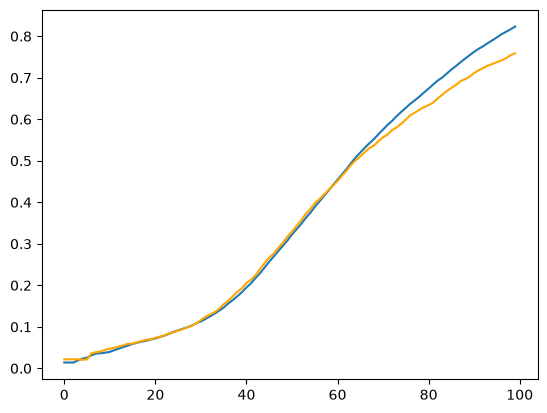

In [119]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'],color='orange')

In [120]:
model.predict(X[final_training_index:])

142/142 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([[4.20472185e-10, 3.79758811e-12, 2.94805647e-09, ...,
        5.81107731e-12, 1.39922218e-09, 1.90905295e-11],
       [6.60144217e-10, 6.26604468e-17, 6.36842534e-09, ...,
        2.02446254e-10, 4.70319530e-13, 1.13360621e-09],
       [3.72341324e-10, 6.71110006e-15, 1.46306425e-08, ...,
        3.09918446e-09, 1.41779611e-12, 1.12281150e-10],
       ...,
       [1.00270280e-12, 1.33379552e-16, 1.17963916e-09, ...,
        1.60301300e-10, 2.44540690e-11, 7.90154608e-09],
       [5.13666498e-10, 9.86278381e-18, 2.07261728e-08, ...,
        9.65390967e-09, 1.07519340e-13, 5.11889364e-10],
       [1.68723044e-08, 2.77639206e-14, 3.75552958e-07, ...,
        5.27698454e-08, 1.21029783e-10, 4.95335652e-13]], dtype=float32)

In [121]:
predictions = model.predict(X[final_training_index:])

142/142 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [122]:
for index,element in enumerate(predictions):
    predicted = element.argmax()
    predictions[index,:] = 0
    predictions[index,predicted] = 1

In [123]:
predictions.shape

(4532, 4909)

In [124]:
from sklearn.metrics import accuracy_score

In [125]:
accuracy_score(y[final_training_index:],predictions)

0.7879523389232127

In [126]:
def print_prediction(context,index, prediction_vector):
    context_index = context[index]
    print(context_index)

In [127]:
context_window

[['europe', 'continent', 'westernmost', 'peninsulas'],
 ['continent', 'comprising', 'peninsulas', 'eurasia'],
 ['comprising', 'westernmost', 'eurasia', 'located'],
 ['westernmost', 'peninsulas', 'located', 'entirely'],
 ['peninsulas', 'eurasia', 'entirely', 'northern'],
 ['eurasia', 'located', 'northern', 'hemisphere'],
 ['located', 'entirely', 'hemisphere', 'mostly'],
 ['entirely', 'northern', 'mostly', 'eastern'],
 ['northern', 'hemisphere', 'eastern', 'hemisphere'],
 ['hemisphere', 'mostly', 'hemisphere', 'shares'],
 ['mostly', 'eastern', 'shares', 'continental'],
 ['eastern', 'hemisphere', 'continental', 'landmass'],
 ['hemisphere', 'shares', 'landmass', 'afroeurasia'],
 ['shares', 'continental', 'afroeurasia', 'africa'],
 ['continental', 'landmass', 'africa', 'asia'],
 ['landmass', 'afroeurasia', 'asia', 'bordered'],
 ['afroeurasia', 'africa', 'bordered', 'arctic'],
 ['africa', 'asia', 'arctic', 'ocean'],
 ['asia', 'bordered', 'ocean', 'north'],
 ['bordered', 'arctic', 'north', 'a

In [128]:
print_prediction(context_window,20,predictions)

['arctic', 'ocean', 'atlantic', 'ocean']


In [135]:
def print_prediction(context,index, prediction_vector):
    context_index = context[index] 
    predicted_word = prediction_vector[index]
    
    for index_word, array in enumerate(vocab_arrays.values()):
        if  np.array_equal(predicted_word, array):
            predicted_word = vocab[index_word]
    print(context_index)
    print(predicted_word)

In [136]:
print_prediction(context_window[final_training_index:],20,predictions)

['nevada', 'cascade', 'ranges', 'run']
mountain


In [137]:
print_prediction(context_window[final_training_index:],21,predictions)

['cascade', 'mountain', 'run', 'close']
ranges


In [138]:
print_prediction(context_window[final_training_index:],150,predictions)

['overall', 'united', 'receives', 'highimpact']
states


In [139]:
print_prediction(context_window[final_training_index:],151,predictions)

['united', 'states', 'highimpact', 'extreme']
receives


In [140]:
model

<Sequential name=sequential_1, built=True>

In [141]:
model.get_weights()

[array([[ 0.52382576, -0.8728394 ,  0.30239704, ..., -0.94245225,
         -0.4420733 , -0.5998198 ],
        [ 0.05104365,  0.74931854,  0.09090749, ...,  1.7445534 ,
         -0.0061707 ,  1.0366983 ],
        [ 1.0945691 ,  0.8681913 ,  0.6039319 , ...,  1.1436883 ,
          0.16175736, -0.31580725],
        ...,
        [-0.16138852, -0.5936645 ,  1.9746324 , ...,  1.680865  ,
          0.9409545 ,  0.0531647 ],
        [ 0.23021746,  1.2125788 ,  1.9457315 , ...,  0.7496557 ,
          0.02762239,  1.8920938 ],
        [ 0.9217836 ,  2.0324667 ,  0.8351217 , ...,  1.3959068 ,
         -0.329609  ,  1.8751147 ]], dtype=float32),
 array([0.9967415 , 1.2130282 , 1.1898282 , 0.9751217 , 0.95384073,
        1.1687211 , 1.1639845 , 0.93131065, 0.9180732 , 1.211743  ,
        0.95766956, 0.929207  , 0.932354  , 1.2489879 , 1.2142054 ,
        0.9726591 , 0.9874109 , 0.9662426 , 0.9357447 , 1.1677183 ,
        0.9394712 , 1.2640277 , 0.91374236, 0.9468449 , 0.9424716 ,
        0.9918386 

In [142]:
len(model.get_weights())

4

In [143]:
model.get_weights()[0]

array([[ 0.52382576, -0.8728394 ,  0.30239704, ..., -0.94245225,
        -0.4420733 , -0.5998198 ],
       [ 0.05104365,  0.74931854,  0.09090749, ...,  1.7445534 ,
        -0.0061707 ,  1.0366983 ],
       [ 1.0945691 ,  0.8681913 ,  0.6039319 , ...,  1.1436883 ,
         0.16175736, -0.31580725],
       ...,
       [-0.16138852, -0.5936645 ,  1.9746324 , ...,  1.680865  ,
         0.9409545 ,  0.0531647 ],
       [ 0.23021746,  1.2125788 ,  1.9457315 , ...,  0.7496557 ,
         0.02762239,  1.8920938 ],
       [ 0.9217836 ,  2.0324667 ,  0.8351217 , ...,  1.3959068 ,
        -0.329609  ,  1.8751147 ]], dtype=float32)

In [144]:
pd.DataFrame(model.get_weights()[0],index=vocab)

,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
abandoning,0.523826,-0.872839,0.302397,1.138276,-0.435648,1.343786,-1.016288,0.656996,1.306140,0.699129,...,-0.633879,0.722066,1.099019,0.514743,0.833954,1.022970,0.662649,-0.942452,-0.442073,-0.599820
abbreviation,0.051044,0.749319,0.090907,-0.944524,-1.000963,-0.064820,1.664144,-1.463519,0.841679,0.112346,...,-0.185791,0.829998,-0.467773,0.917777,-0.905495,-0.611688,-1.505547,1.744553,-0.006171,1.036698
abc,1.094569,0.868191,0.603932,1.827036,0.215728,0.672615,-0.318754,-0.902239,0.416404,1.824243,...,1.183872,1.532776,-1.148955,0.884911,-1.020698,-0.883129,1.629412,1.143688,0.161757,-0.315807
abolished,0.124862,1.290342,-1.297136,0.167152,-0.545515,1.360658,-0.073846,-0.485415,1.211256,0.901226,...,0.104689,0.573976,0.571454,-1.010151,-0.793368,-0.700696,0.889048,-0.439527,0.495031,1.072042
abolishment,0.494830,-0.348767,-0.268041,1.570163,1.430094,1.731690,0.139792,1.125479,-1.163334,-0.124555,...,1.849272,2.081291,0.913254,-0.406897,-0.769391,-0.873027,0.647890,2.145451,-0.548799,-1.227952
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ヨーロッパ,-1.355132,-0.564159,0.452614,0.660377,-0.038022,0.211976,-0.399841,0.969055,0.750106,-1.284918,...,0.598844,-0.969064,-0.840110,1.402718,0.546659,-0.786625,-0.613903,-0.703151,-0.707714,0.692575
欧州,1.717000,0.194849,0.145024,-1.020617,-0.183417,-0.110099,0.495231,0.743625,0.902578,0.503123,...,0.277290,1.444466,0.112278,-0.010496,-1.159174,-0.791467,0.034683,-0.437346,0.477833,-0.900601
欧州連合,-0.161389,-0.593665,1.974632,-0.134465,-1.246609,-1.725321,1.382373,-0.987013,0.935331,0.494436,...,1.916125,-0.310345,0.272477,1.160364,-1.775727,-0.597428,0.683610,1.680865,0.940955,0.053165
歐洲欧洲,0.230217,1.212579,1.945732,-0.329593,-1.064651,0.784151,1.714323,-1.025389,-0.219099,0.177307,...,1.872153,1.625053,-1.238649,1.288144,-1.549304,-1.652019,-0.908422,0.749656,0.027622,1.892094


In [145]:
layer_1 = pd.DataFrame(model.get_weights()[0],index=vocab)
layer_2 = pd.DataFrame(model.get_weights()[2].T,index=vocab)

In [147]:
combined_layers = (layer_1+layer_2)/2
combined_layers

,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
abandoning,0.296450,-0.511188,0.339034,0.660117,-0.443422,0.833840,-2.136214,0.314580,0.507597,0.559987,...,-1.281473,-0.179122,0.684133,0.090059,0.507371,0.289686,0.267610,-0.410063,-0.359674,-2.459596
abbreviation,0.015662,0.437317,0.122530,-0.602942,-1.417870,-0.061042,1.035434,-1.311725,0.421187,-0.264808,...,-0.083882,0.571729,-0.393587,0.688479,-1.823787,-1.354777,-1.882015,1.007072,-0.194992,0.700376
abc,0.587109,0.633868,-0.075933,0.919995,0.006103,-1.815440,-1.682958,-0.430495,-0.134480,1.174010,...,0.831212,1.006482,-0.870324,0.679463,-0.594632,-0.629386,0.833589,0.696526,-0.128477,-0.460515
abolished,0.085287,0.554757,-1.391550,0.224297,-0.385348,0.365296,-0.233850,-0.108743,0.614575,-0.033040,...,0.048494,0.331297,0.373874,-1.353597,-0.581879,-0.802325,0.631765,0.125530,0.361489,0.431306
abolishment,0.225002,-0.400332,-0.447229,0.814148,0.730717,1.035232,-0.079703,0.330843,-0.702925,0.033471,...,1.131071,1.092865,0.631953,-0.328550,-0.565849,-0.478686,0.361226,1.322208,-0.416408,-1.871809
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ヨーロッパ,-0.667042,-0.248594,0.380043,0.354694,0.095620,0.131505,-0.166470,0.612140,0.477280,-1.254674,...,0.420740,-1.226544,-1.002623,0.808668,0.070464,-0.442920,-0.944596,-0.295940,-0.810211,0.362299
欧州,0.855978,-0.337426,-0.551686,-0.677695,-1.144039,0.043523,-1.034561,0.394489,0.343332,0.364249,...,0.242370,0.745975,0.101703,-0.055936,-0.580082,-0.345625,0.025688,-0.380712,0.219521,-1.068225
欧州連合,-0.342983,-0.781854,1.149933,-0.325761,-0.714676,-1.190801,0.699899,-0.784021,0.026411,0.413169,...,1.051634,-0.160029,0.133079,0.727868,-1.299441,-0.361408,0.395314,1.030153,0.513264,0.066335
歐洲欧洲,0.040148,0.732368,0.903467,-0.468025,-1.486377,0.118691,0.994633,-1.753391,-0.192836,-0.213131,...,0.999645,0.849257,-0.967069,0.747489,-1.764216,-1.068543,-1.844344,0.419458,-0.190518,1.104079


In [148]:
from sklearn.metrics.pairwise import cosine_similarity
cosine_similarity(combined_layers)

/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


array([[ 1.        , -0.2649117 ,  0.2417905 , ..., -0.05778473,
        -0.3602347 , -0.18459553],
       [-0.2649117 ,  0.99999994,  0.03073007, ...,  0.21376714,
         0.91648567,  0.50493944],
       [ 0.2417905 ,  0.03073007,  0.99999994, ...,  0.31316188,
         0.04901537,  0.03605306],
       ...,
       [-0.05778473,  0.21376714,  0.31316188, ...,  0.99999994,
         0.25298402,  0.37571606],
       [-0.3602347 ,  0.91648567,  0.04901537, ...,  0.25298402,
         0.99999994,  0.517512  ],
       [-0.18459553,  0.50493944,  0.03605306, ...,  0.37571606,
         0.517512  ,  0.99999994]], dtype=float32)

In [149]:
distances = pd.DataFrame(cosine_similarity(combined_layers),index=vocab,columns=vocab)
distances

/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,abandoning,abbreviation,abc,abolished,abolishment,abolition,abolitionism,abortion,abovementioned,abraham,...,ōuzhōu,εὐρύς,εὐρώπη,ὠπός,ὤψ,ヨーロッパ,欧州,欧州連合,歐洲欧洲,歐羅巴洲
abandoning,1.000000,-0.264912,0.241791,-0.123995,0.283703,-0.046237,-0.226787,-0.033094,0.169992,0.137254,...,-0.324398,-0.074724,-0.154556,-0.299679,-0.125750,0.030024,0.172105,-0.057785,-0.360235,-0.184596
abbreviation,-0.264912,1.000000,0.030730,-0.096425,-0.074185,-0.200813,-0.024070,0.080369,-0.561278,0.325503,...,0.842092,0.254263,0.419094,0.711000,0.393644,0.316262,0.143736,0.213767,0.916486,0.504939
abc,0.241791,0.030730,1.000000,-0.122803,0.318452,0.067629,0.052557,0.257499,-0.072404,0.172216,...,0.151146,-0.011129,-0.263899,0.074701,0.191838,-0.042749,0.260610,0.313162,0.049015,0.036053
abolished,-0.123995,-0.096425,-0.122803,1.000000,0.178014,0.366126,0.006033,-0.085628,-0.034013,-0.253812,...,-0.130711,-0.125163,-0.059602,0.106793,0.118994,-0.018793,0.072008,0.237865,-0.090198,0.257451
abolishment,0.283703,-0.074185,0.318452,0.178014,1.000000,0.503917,0.109278,0.127637,-0.362427,0.365227,...,0.072353,0.271594,-0.096916,0.072084,0.114633,0.002695,-0.078459,0.264110,0.019736,-0.008978
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ヨーロッパ,0.030024,0.316262,-0.042749,-0.018793,0.002695,-0.185280,0.115725,0.152710,-0.184946,0.138659,...,0.278234,-0.137520,-0.019827,0.252236,0.022380,1.000000,0.015513,0.482709,0.287495,0.282326
欧州,0.172105,0.143736,0.260610,0.072008,-0.078459,-0.203596,-0.308441,0.155635,0.028764,-0.148229,...,0.110764,0.212252,0.266632,0.294986,0.408929,0.015513,1.000000,0.155613,0.089458,0.017985
欧州連合,-0.057785,0.213767,0.313162,0.237865,0.264110,0.167065,0.125157,0.128662,-0.213174,0.121807,...,0.244389,0.083629,-0.148605,0.312199,0.351190,0.482709,0.155613,1.000000,0.252984,0.375716
歐洲欧洲,-0.360235,0.916486,0.049015,-0.090198,0.019736,-0.080802,0.015081,0.141669,-0.615282,0.426685,...,0.941914,0.297395,0.413283,0.725239,0.410224,0.287495,0.089458,0.252984,1.000000,0.517512


In [152]:
word = 'abolished'
distances.loc[word].sort_values(ascending=False)[1:21]

schengen        0.713427
herzegovina     0.619383
nationally      0.613481
borderfree      0.609918
preservation    0.595703
area            0.592627
square          0.580831
surface         0.577020
moon            0.572332
doubled         0.559207
ruhr            0.552565
land            0.533668
quarter         0.486895
driven          0.485014
miles           0.475184
send            0.472606
gun             0.468548
india           0.456351
petersburg      0.455216
amounted        0.454846
Name: abolished, dtype: float32

In [156]:
def get_most_least_similar_words(word):
    similar_words = distances.loc[word].sort_values(ascending=False)[1:21]
    least_similar_words = distances.loc[word].sort_values(ascending=True)[0:20]
    return similar_words, least_similar_words

In [159]:
get_most_least_similar_words('usa')

(post            0.765893
 publications    0.683137
 today           0.559542
 commonly        0.552795
 comprise        0.543356
 plunder         0.512323
 writers         0.508672
 hominin         0.497168
 geology         0.492816
 bit             0.489276
 intervals       0.483472
 irving          0.483136
 thousands       0.481376
 prescription    0.469609
 resided         0.468435
 cultures        0.459108
 shores          0.458704
 order           0.454439
 blues           0.441946
 swept           0.439668
 Name: usa, dtype: float32,
 poor           -0.479788
 persisted      -0.477472
 factors        -0.455547
 slavery        -0.453452
 complement     -0.447838
 preservation   -0.447606
 unions         -0.439510
 exception      -0.434376
 considers      -0.430488
 beekes         -0.414975
 siege          -0.410906
 newspapers     -0.409197
 legislation    -0.403879
 worms          -0.397540
 diet           -0.397467
 seizing        -0.389545
 culminating    -0.388825
 males    

In [161]:
get_most_least_similar_words('spanish')

(rico            0.767588
 expedition      0.754344
 armada          0.753953
 armadas         0.735203
 miracle         0.682302
 guam            0.645973
 portuguese      0.626606
 puerto          0.620825
 publications    0.612333
 churchs         0.580003
 commonly        0.577495
 retain          0.570404
 oceans          0.563090
 chamorro        0.549561
 failed          0.537014
 extended        0.526556
 fleet           0.515331
 samoan          0.514702
 resulting       0.511165
 halves          0.505126
 Name: spanish, dtype: float32,
 death          -0.460448
 suggests       -0.449899
 instability    -0.441804
 smaller        -0.435466
 cocacola       -0.432004
 disney         -0.420632
 prewar         -0.418077
 activitiesof   -0.418014
 remote         -0.411218
 traffic        -0.409114
 secularism     -0.405425
 suffer         -0.402818
 regard         -0.400810
 figure         -0.400010
 collisions     -0.391980
 oldest         -0.388463
 louis          -0.387955
 stagn

In [ ]:
get_most_least_similar_words('plague')

(lepers         0.791212
 beggars        0.782542
 effect         0.742134
 thought        0.726564
 returned       0.726318
 timethe        0.687537
 epidemics      0.684646
 sites          0.682400
 swept          0.649212
 devastating    0.645489
 heaviest       0.606599
 carolingian    0.603670
 earliest       0.583823
 collisions     0.545269
 catholics      0.542111
 settled        0.536817
 moldavia       0.535766
 pechenegs      0.521810
 loss           0.520619
 meal           0.512054
 Name: plague, dtype: float32,
 vietnam            -0.573659
 opposition         -0.538438
 worldextreme       -0.526201
 deadliest          -0.522241
 fueled             -0.508412
 southwest          -0.489208
 commanderinchief   -0.479697
 weather            -0.469052
 novel              -0.462539
 cbs                -0.456142
 incidents          -0.447508
 site               -0.445431
 extends            -0.445009
 involvement        -0.443680
 civil              -0.443481
 rates             

In [163]:
get_most_least_similar_words('portugal')

(spain             0.722184
 greatest          0.721509
 belgium           0.705651
 netherlands       0.658534
 ally              0.647666
 frontiers         0.630966
 seek              0.590287
 joining           0.583872
 france            0.572107
 putting           0.567246
 overtaking        0.561960
 justice           0.555068
 serbia            0.546174
 uk                0.542576
 britannia         0.540112
 england           0.539267
 hispania          0.518681
 ireland           0.515590
 led               0.509336
 unsuccessfully    0.500387
 Name: portugal, dtype: float32,
 confront      -0.525455
 nonviolence   -0.486369
 monastic      -0.479370
 racism        -0.476833
 democrat      -0.472849
 google        -0.471819
 violence      -0.465614
 owns          -0.462000
 sinatra       -0.449024
 maghreb       -0.448964
 mining        -0.445014
 wildlife      -0.444401
 complement    -0.444200
 casually      -0.442990
 yield         -0.441307
 dobyns        -0.438174
 monume

In [165]:
get_most_least_similar_words('democracy')

(uniformly         0.669373
 lawmajor          0.666386
 representative    0.647372
 classify          0.640131
 liberal           0.639757
 indexes           0.591818
 corruption        0.579069
 perceptions       0.576460
 equality          0.532598
 parliamentary     0.525481
 cases             0.520660
 index             0.502140
 uprisings         0.488104
 consent           0.487118
 governed          0.486531
 russias           0.484823
 forum             0.482511
 celebrities       0.463117
 monoculture       0.455359
 permissive        0.452648
 Name: democracy, dtype: float32,
 july             -0.500949
 farther          -0.476005
 old              -0.471765
 geological       -0.434958
 sioux            -0.427559
 chain            -0.413116
 west             -0.408588
 dakota           -0.408252
 annually         -0.405296
 introducing      -0.395572
 improving        -0.393074
 female           -0.371553
 philadelphiaon   -0.370373
 fragments        -0.370224
 boomed       

In [167]:
get_most_least_similar_words('dogs')

(pioneered        0.998618
 openstreetmap    0.998507
 eventseight      0.998503
 occasionthe      0.998492
 statesthe        0.998479
 tacos            0.998394
 evolved          0.998383
 earnings         0.998372
 volleyball       0.998367
 attract          0.998347
 macaroni         0.998329
 watched          0.998328
 doughnuts        0.998322
 football         0.998309
 burritos         0.998304
 cohost           0.998268
 basketball       0.998255
 information      0.998234
 forecasts        0.998232
 stateshistory    0.998215
 Name: dogs, dtype: float32,
 taught          -0.259061
 maine           -0.258002
 tributary       -0.236456
 absorbed        -0.232341
 entered         -0.232187
 originated      -0.232043
 powerful        -0.223829
 accounting      -0.223485
 recognized      -0.220878
 rocky           -0.216528
 refer           -0.214528
 semiarid        -0.213763
 colonial        -0.211933
 skyscraper      -0.210058
 awakening       -0.209776
 day             -0.208325

In [168]:
get_most_least_similar_words('science')

(galen          0.747666
 atrisk         0.731255
 pythagoras     0.699734
 technology     0.677972
 hippocrates    0.676020
 art            0.661620
 euclid         0.657331
 arose          0.635502
 workers        0.604456
 contributed    0.598346
 kooning        0.588740
 popular        0.582192
 develop        0.557617
 pop            0.544170
 andy           0.536516
 mutual         0.533784
 rival          0.524509
 modernist      0.520899
 variously      0.520469
 bing           0.518401
 Name: science, dtype: float32,
 prewar         -0.527923
 archipelago    -0.509840
 coastal        -0.486297
 wedge          -0.454252
 bhutan         -0.441848
 sectarian      -0.435359
 centered       -0.427235
 canadathe      -0.412445
 lithuanian     -0.412188
 oceanic        -0.411244
 sony           -0.406209
 maine          -0.402325
 namely         -0.399977
 southwestern   -0.391849
 shore          -0.388684
 regarding      -0.385988
 falling        -0.385001
 celtic         -0.382507
